In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json

In [2]:
import json
import pandas as pd


def load_guidellm_multidim(json_data_or_filepath):
    # Load JSON if file path is passed
    if isinstance(json_data_or_filepath, str):
        with open(json_data_or_filepath, "r") as f:
            data = json.load(f)
    else:
        data = json_data_or_filepath

    bm = data["benchmarks"][0]
    sched = bm["scheduler_state"]
    m = bm["metrics"]

    # --- 1. Run Summary Info ---
    start_str = pd.to_datetime(sched["start_time"], unit="s").strftime("%H:%M:%S")
    end_str = pd.to_datetime(sched["end_time"], unit="s").strftime("%H:%M:%S")
    dur_sec = round(sched["end_time"] - sched["start_time"], 1)

    summary_cols = pd.MultiIndex.from_tuples(
        [
            ("Benchmark", "Strategy"),
            ("Timings", "Start"),
            ("Timings", "End"),
            ("Timings", "Dur Sec"),
            ("Timings", "Warm Sec"),
            ("Timings", "Cool Sec"),
            ("Input Tokens", "Comp Tot"),
            ("Input Tokens", "Inc Tot"),
            ("Input Tokens", "Err Tot"),
            ("Output Tokens", "Comp Tot"),
            ("Output Tokens", "Inc Tot"),
            ("Output Tokens", "Err Tot"),
        ]
    )

    summary_data = [
        [
            "poisson",
            start_str,
            end_str,
            dur_sec,
            0.0,
            0.0,
            m["prompt_token_count"]["successful"]["total_sum"],
            0.0,
            0.0,
            m["output_token_count"]["successful"]["total_sum"],
            0.0,
            0.0,
        ]
    ]

    df_summary = pd.DataFrame(summary_data, columns=summary_cols)

    # --- 2. Request Token Statistics ---
    req_tok_cols = pd.MultiIndex.from_tuples(
        [
            ("Benchmark", "Strategy"),
            ("Input Tok Per Req", "Mdn"),
            ("Input Tok Per Req", "p95"),
            ("Output Tok Per Req", "Mdn"),
            ("Output Tok Per Req", "p95"),
            ("Total Tok Per Req", "Mdn"),
            ("Total Tok Per Req", "p95"),
            ("Stream Iter Per Req", "Mdn"),
            ("Stream Iter Per Req", "p95"),
            ("Output Tok Per Stream Iter", "Mdn"),
            ("Output Tok Per Stream Iter", "p95"),
        ]
    )

    req_tok_data = [
        [
            "poisson",
            m["prompt_token_count"]["successful"]["percentiles"]["p50"],
            m["prompt_token_count"]["successful"]["percentiles"]["p95"],
            m["output_token_count"]["successful"]["percentiles"]["p50"],
            m["output_token_count"]["successful"]["percentiles"]["p95"],
            m["total_token_count"]["successful"]["percentiles"]["p50"],
            m["total_token_count"]["successful"]["percentiles"]["p95"],
            m["request_streaming_iterations_count"]["successful"]["percentiles"][
                "p50"
            ],
            m["request_streaming_iterations_count"]["successful"]["percentiles"][
                "p95"
            ],
            1.0,
            1.0,
        ]
    ]

    df_req_tok = pd.DataFrame(req_tok_data, columns=req_tok_cols)

    # --- 3. Request Latency Statistics ---
    latency_cols = pd.MultiIndex.from_tuples(
        [
            ("Benchmark", "Strategy"),
            ("Request Latency", "Sec Mdn"),
            ("Request Latency", "Sec p95"),
            ("TTFT", "ms Mdn"),
            ("TTFT", "ms p95"),
            ("TTFOT", "ms Mdn"),
            ("TTFOT", "ms p95"),
            ("ITL", "ms Mdn"),
            ("ITL", "ms p95"),
            ("TPOT", "ms Mdn"),
            ("TPOT", "ms p95"),
        ]
    )

    latency_data = [
        [
            "poisson",
            round(m["request_latency"]["successful"]["percentiles"]["p50"], 1),
            round(m["request_latency"]["successful"]["percentiles"]["p95"], 1),
            round(m["time_to_first_token_ms"]["successful"]["percentiles"]["p50"], 1),
            round(m["time_to_first_token_ms"]["successful"]["percentiles"]["p95"], 1),
            round(
                m["time_to_first_output_token_ms"]["successful"]["percentiles"]["p50"],
                1,
            ),
            round(
                m["time_to_first_output_token_ms"]["successful"]["percentiles"]["p95"],
                1,
            ),
            round(m["inter_token_latency_ms"]["successful"]["percentiles"]["p50"], 1),
            round(m["inter_token_latency_ms"]["successful"]["percentiles"]["p95"], 1),
            round(
                m["time_per_output_token_ms"]["successful"]["percentiles"]["p50"], 1
            ),
            round(
                m["time_per_output_token_ms"]["successful"]["percentiles"]["p95"], 1
            ),
        ]
    ]

    df_latency = pd.DataFrame(latency_data, columns=latency_cols)

    # --- 4. Server Throughput Statistics ---
    throughput_cols = pd.MultiIndex.from_tuples(
        [
            ("Benchmark", "Strategy"),
            ("Requests Concurrency", "Mdn"),
            ("Requests Concurrency", "Mean"),
            ("Requests Per Sec", "Mean"),
            ("Input Tokens Per Sec", "Mean"),
            ("Output Tokens Per Sec", "Mean"),
            ("Total Tokens Per Sec", "Mean"),
        ]
    )

    throughput_data = [
        [
            "poisson",
            m["request_concurrency"]["total"]["percentiles"]["p50"],
            round(m["request_concurrency"]["total"]["mean"], 1),
            round(m["requests_per_second"]["total"]["mean"], 1),
            round(m["prompt_tokens_per_second"]["total"]["mean"], 1),
            round(m["output_tokens_per_second"]["total"]["mean"], 1),
            round(
                m["prompt_tokens_per_second"]["total"]["mean"]
                + m["output_tokens_per_second"]["total"]["mean"],
                1,
            ),
        ]
    ]

    df_throughput = pd.DataFrame(throughput_data, columns=throughput_cols)

    return {
        "run_summary": df_summary,
        "request_tokens": df_req_tok,
        "latency": df_latency,
        "throughput": df_throughput,
    }


# Usage Example:
# dfs = load_guidellm_multidim("guidellm_data.json")
# print(dfs["latency"])

In [3]:
from typing import Dict, List, Union
import matplotlib.pyplot as plt
import pandas as pd


def plot_metrics_from_df(
    df: pd.DataFrame,
    metrics: Union[str, List[str]],
    timestamp_col: str = "timestamp",
    title: str = "vLLM Server Metrics Over Time",
):
    """Plots one or multiple metrics against time from a pandas DataFrame.

    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame containing the metric logs.
    metrics : str or list of str
        Column name or list of column names to plot.
    timestamp_col : str
        Column name holding the time/timestamp data (default: 'timestamp').
    title : str
        Custom plot title.
    """
    plot_df = df.copy()

    # Ensure metrics parameter is a list
    if isinstance(metrics, str):
        metrics = [metrics]

    # Convert timestamp to datetime
    plot_df[timestamp_col] = pd.to_numeric(plot_df[timestamp_col])
    plot_df["datetime"] = pd.to_datetime(plot_df[timestamp_col], unit="s")

    plt.figure(figsize=(11, 5), dpi=100)

    # Plot each requested metric
    for metric in metrics:
        if metric not in plot_df.columns:
            print(f"Warning: Column '{metric}' not found in DataFrame. Skipping.")
            continue

        plot_df[metric] = pd.to_numeric(plot_df[metric])

        # Auto-scale cache hit rates or usage percentages if expressed as 0.0 - 1.0
        y_values = plot_df[metric]
        label_name = metric.replace("_", " ").title()

        if "hit_rate" in metric or "usage_perc" in metric:
            if y_values.max() <= 1.0:
                y_values = y_values * 100.0
                label_name += " (%)"

        plt.plot(
            plot_df["datetime"],
            y_values,
            marker="o",
            markersize=3,
            linewidth=2,
            label=label_name,
        )

    plt.title(title, fontsize=13, fontweight="bold")
    plt.xlabel("Time (HH:MM:SS)", fontsize=11)
    plt.ylabel("Metric Values", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend(loc="upper left")
    plt.tight_layout()

    plt.show()

In [4]:
benchmark_b_path = "../results/exp2/vllm-rag-baseline-fp16-cache.json"
metrics_b_path = '../results/exp2/vllm_metrics_baseline.json'


benchmark_o_path = "../results/exp2/vllm-rag-optimized-fp16-cache.json"
metrics_o_path = '../results/exp2/vllm_metrics_optimized.json'

benchmark_q_path = "../results/exp2/vllm-rag-quantized-8fp-cache.json"
metrics_q_path = '../results/exp2/vllm_metrics_quantized.json'

benchmark_con_path = "../results/exp2/vllm-rag-optimized-8fp-concurrent.json"
metrics_con_path = '../results/exp2/vllm_metrics_quantized_concurrent.json'

In [5]:
with open(benchmark_b_path, 'r') as file:
    data = json.load(file)

In [6]:
bmark_b_data = load_guidellm_multidim(benchmark_b_path)
with open(metrics_b_path, 'r') as file:
    metrics_b_df = pd.DataFrame(json.load(file))


bmark_o_data = load_guidellm_multidim(benchmark_o_path)
with open(metrics_o_path, 'r') as file:
    metrics_o_df = pd.DataFrame(json.load(file))

bmark_q_data = load_guidellm_multidim(benchmark_q_path)
with open(metrics_q_path, 'r') as file:
    metrics_q_df = pd.DataFrame(json.load(file))

bmark_con_data = load_guidellm_multidim(benchmark_con_path)
with open(metrics_con_path, 'r') as file:
    metrics_con_df = pd.DataFrame(json.load(file))

# summary

In [7]:
bmark_b_data.keys()

dict_keys(['run_summary', 'request_tokens', 'latency', 'throughput'])

In [8]:
bmark_b_data['run_summary']

Benchmark   Timings                                     Input Tokens  \
   Strategy     Start       End Dur Sec Warm Sec Cool Sec     Comp Tot   
0   poisson  06:18:26  06:44:38  1572.6      0.0      0.0    2559984.0   

                  Output Tokens                  
  Inc Tot Err Tot      Comp Tot Inc Tot Err Tot  
0     0.0     0.0      227747.0     0.0     0.0

In [9]:
bmark_o_data['run_summary']

Benchmark   Timings                                     Input Tokens  \
   Strategy     Start       End Dur Sec Warm Sec Cool Sec     Comp Tot   
0   poisson  06:49:27  06:56:32   425.3      0.0      0.0    2561200.0   

                  Output Tokens                  
  Inc Tot Err Tot      Comp Tot Inc Tot Err Tot  
0     0.0     0.0      227913.0     0.0     0.0

In [10]:
bmark_q_data['run_summary']

Benchmark   Timings                                     Input Tokens  \
   Strategy     Start       End Dur Sec Warm Sec Cool Sec     Comp Tot   
0   poisson  07:20:10  07:24:47   277.0      0.0      0.0    2561200.0   

                  Output Tokens                  
  Inc Tot Err Tot      Comp Tot Inc Tot Err Tot  
0     0.0     0.0      231055.0     0.0     0.0

# request tokens

In [11]:
bmark_b_data['request_tokens']

Benchmark Input Tok Per Req         Output Tok Per Req         \
   Strategy               Mdn     p95                Mdn    p95   
0   poisson            1302.0  1326.0               95.0  242.0   

  Total Tok Per Req         Stream Iter Per Req         \
                Mdn     p95                 Mdn    p95   
0            1380.0  1546.0                98.0  245.0   

  Output Tok Per Stream Iter       
                         Mdn  p95  
0                        1.0  1.0

In [12]:
bmark_o_data['request_tokens']

Benchmark Input Tok Per Req         Output Tok Per Req         \
   Strategy               Mdn     p95                Mdn    p95   
0   poisson            1302.0  1326.0               96.0  238.0   

  Total Tok Per Req         Stream Iter Per Req         \
                Mdn     p95                 Mdn    p95   
0            1379.0  1548.0                99.0  241.0   

  Output Tok Per Stream Iter       
                         Mdn  p95  
0                        1.0  1.0

In [13]:
bmark_q_data['request_tokens']

Benchmark Input Tok Per Req         Output Tok Per Req         \
   Strategy               Mdn     p95                Mdn    p95   
0   poisson            1302.0  1326.0               97.0  235.0   

  Total Tok Per Req         Stream Iter Per Req         \
                Mdn     p95                 Mdn    p95   
0            1381.0  1539.0               100.0  238.0   

  Output Tok Per Stream Iter       
                         Mdn  p95  
0                        1.0  1.0

# Latency

In [14]:
bmark_b_data['latency']

Benchmark Request Latency             TTFT             TTFOT           \
   Strategy         Sec Mdn Sec p95   ms Mdn   ms p95   ms Mdn   ms p95   
0   poisson            98.0   119.3  83497.9  89395.0  83497.9  89395.0   

     ITL          TPOT          
  ms Mdn ms p95 ms Mdn  ms p95  
0  145.0  162.4  746.2  1616.6

In [15]:
bmark_o_data['latency']

Benchmark Request Latency             TTFT             TTFOT           \
   Strategy         Sec Mdn Sec p95   ms Mdn   ms p95   ms Mdn   ms p95   
0   poisson            24.1    42.1  11517.8  15433.6  11517.8  15433.6   

     ITL          TPOT         
  ms Mdn ms p95 ms Mdn ms p95  
0  128.1  146.4  207.5  339.7

In [16]:
bmark_q_data['latency']

Benchmark Request Latency           TTFT         TTFOT           ITL         \
   Strategy         Sec Mdn Sec p95 ms Mdn ms p95 ms Mdn ms p95 ms Mdn ms p95   
0   poisson            14.0    33.5  543.7  784.0  543.7  784.0  144.0  150.7   

    TPOT         
  ms Mdn ms p95  
0  147.0  155.7

# Througput

In [17]:
# Requets concurreny: # of in-flight (active) requests
# request per sec: How many requests the server manages to finish per second
# Input Tokens Per Sec: prefil stage
# Output Tokens Per Sec: decode stage
# Total Tokens Per Sec: 

In [18]:
bmark_b_data['throughput']

Benchmark Requests Concurrency        Requests Per Sec Input Tokens Per Sec  \
   Strategy                  Mdn   Mean             Mean                 Mean   
0   poisson                128.0  124.2              1.3               1639.1   

  Output Tokens Per Sec Total Tokens Per Sec  
                   Mean                 Mean  
0                 145.0               1784.1

In [19]:
bmark_o_data['throughput']

Benchmark Requests Concurrency        Requests Per Sec Input Tokens Per Sec  \
   Strategy                  Mdn   Mean             Mean                 Mean   
0   poisson                128.0  121.1              4.7               6337.6   

  Output Tokens Per Sec Total Tokens Per Sec  
                   Mean                 Mean  
0                 538.3               6875.9

In [20]:
bmark_q_data['throughput']

Benchmark Requests Concurrency        Requests Per Sec Input Tokens Per Sec  \
   Strategy                  Mdn   Mean             Mean                 Mean   
0   poisson                128.0  121.3              7.3               9734.0   

  Output Tokens Per Sec Total Tokens Per Sec  
                   Mean                 Mean  
0                 838.7              10572.7

# vLLM

## Cache hit

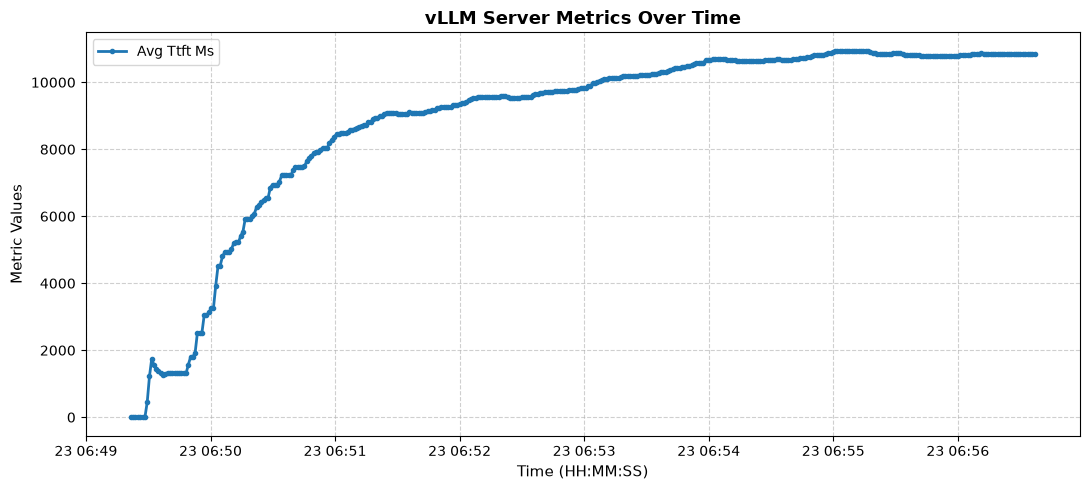

In [21]:
plot_metrics_from_df(
    df=metrics_o_df,
    metrics=["avg_ttft_ms"],
)

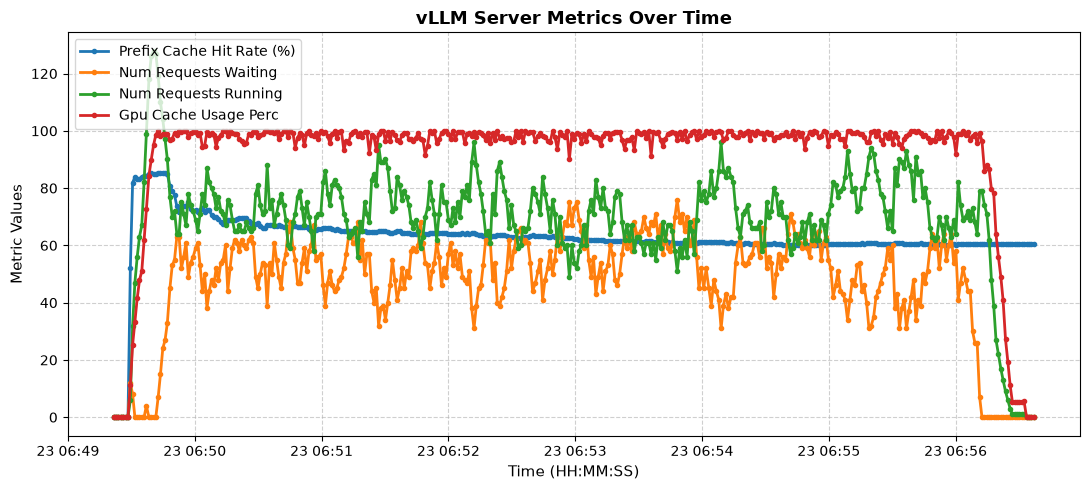

In [22]:
plot_metrics_from_df(
    df=metrics_o_df,
    metrics=["prefix_cache_hit_rate", "num_requests_waiting","num_requests_running", "gpu_cache_usage_perc"],
)

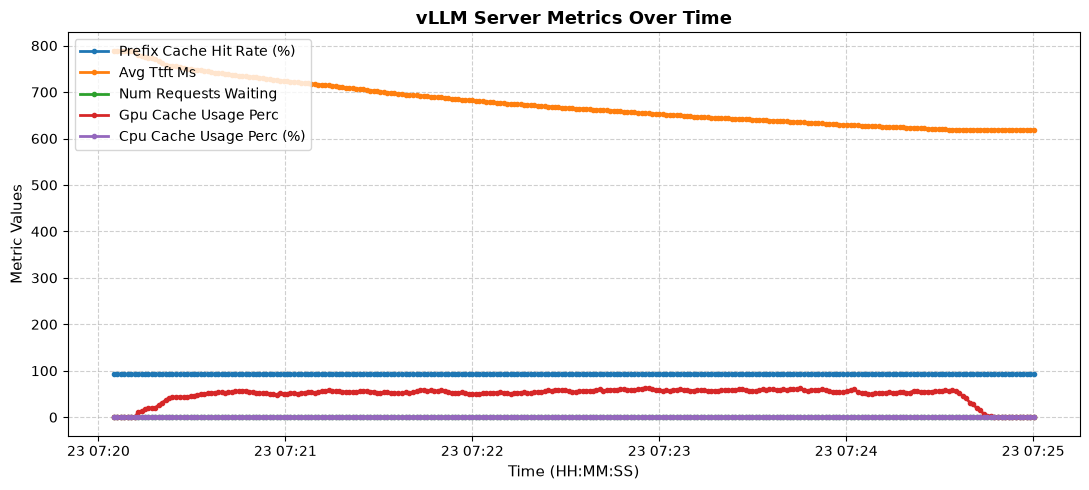

In [23]:
plot_metrics_from_df(
    df=metrics_q_df,
    metrics=["prefix_cache_hit_rate", "avg_ttft_ms", "num_requests_waiting", "gpu_cache_usage_perc", "cpu_cache_usage_perc"],
)

In [24]:
metrics_b_df.columns

Index(['timestamp', 'gpu_cache_usage_perc', 'cpu_cache_usage_perc',
       'num_requests_running', 'num_requests_waiting', 'num_requests_swapped',
       'num_preemptions_total', 'request_queue_time_seconds', 'avg_ttft_ms',
       'avg_e2e_latency_s', 'avg_generation_throughput_toks_per_s',
       'prefix_cache_hit_rate', 'prompt_tokens_total',
       'generation_tokens_total'],
      dtype='str')

# Concurrent

3 Rules to Identify Your Maximum Sustainable Capacity:
1. Target Achieved RPS vs. Target Rate: When Achieved RPS stops matching the input Rate (e.g., target is 32.0 req/s, but server delivers 18.2 req/s), you have surpassed absolute maximum hardware throughput.
2. TTFT Knee (SLA Limit): Your max sustainable load is the highest rate where TTFT (P95) remains acceptable for your application (typically $< 200 \text{ ms}$ or $< 500 \text{ ms}$). Beyond this point, requests sit in vLLM's memory queue waiting for KV-cache blocks.
3. Error Zero-Tolerance: If failed_requests or timeouts occur at a specific rate, step down to the previous rate level.

In [25]:
def get_numeric(value, default=0.0, stat="successful", percentile="p95"):
    """Pull a single float out of a guidellm metric object.

    guidellm nests metrics as {stat: {"mean": ..., "percentiles": {"p50": ...}}}.
    Passing percentile=None falls through to the mean, which is what rate-style
    metrics (requests_per_second) need. Plain numbers pass straight through.
    """
    if value is None:
        return default
    if isinstance(value, (int, float)):
        return float(value)
    if isinstance(value, dict):
        node = value.get(stat) or value.get("total") or {}
        if isinstance(node, dict):
            pcts = node.get("percentiles") or {}
            if percentile and percentile in pcts:
                return float(pcts[percentile])
            if "mean" in node:
                return float(node["mean"])
    try:
        return float(value)
    except (TypeError, ValueError):
        return default


def parse_guidellm_results(data_input: Union[str, Dict]) -> pd.DataFrame:
    # 1. Load data
    if isinstance(data_input, str):
        with open(data_input, "r", encoding="utf-8") as f:
            raw_data = json.load(f)
    else:
        raw_data = data_input

    benchmarks = raw_data.get("benchmarks", [])
    rows = []

    for idx, b in enumerate(benchmarks):
        metrics = b.get("metrics", {})
        config = b.get("config", {})
        strategy = config.get("strategy", {})

        # --- 1. Streams / Concurrency ---
        # Get target configured streams first, fallback to profile schedule or index
        streams_val = strategy.get("streams")
        if streams_val is None:
            profile_streams = config.get("profile", {}).get("streams", [])
            if profile_streams and idx < len(profile_streams):
                streams_val = profile_streams[idx]
            else:
                streams_val = [1, 2, 4, 8, 16, 32, 64, 128, 256, 500][min(idx, 9)]

        streams_int = int(round(get_numeric(streams_val)))

        # --- 2. Achieved RPS ---
        achieved_rps = get_numeric(
            metrics.get("requests_per_second"), stat="total", percentile=None
        )

        # --- 3. TTFT P95 (ms) ---
        ttft_val = get_numeric(metrics.get("time_to_first_token_ms"))

        # --- 4. ITL P95 (ms) ---
        itl_val = get_numeric(metrics.get("inter_token_latency_ms"))

        # --- 5. Failed Request Count ---
        request_totals = metrics.get("request_totals", {})
        errored_count = 0.0
        if isinstance(request_totals, dict):
            errored_count = get_numeric(request_totals.get("errored"), 0.0)

        # --- 6. Health Status Determination ---
        if errored_count > 0 or ttft_val > 2000:
            status = "Overloaded (Unstable Queueing)"
        elif ttft_val > 300:
            status = "Sustained Capacity Knee"
        elif streams_int <= 4:
            status = "Healthy (Optimal Latency)"
        else:
            status = "Healthy (Scaling)"

        rows.append(
            {
                "Streams": streams_int,
                "Achieved RPS": round(achieved_rps, 2),
                "TTFT (P95)": f"~{int(round(ttft_val))} ms",
                "ITL (P95)": f"~{int(round(itl_val))} ms",
                "Server Status": status,
            }
        )

    df = pd.DataFrame(rows)
    if not df.empty:
        df = df.sort_values(by="Streams").reset_index(drop=True)

    return df

In [26]:
json_file_path = "../results/exp2/vllm-rag-optimized-8fp-concurrent.json"
df = parse_guidellm_results(json_file_path)
print(df)

   Streams  Achieved RPS TTFT (P95) ITL (P95)                   Server Status
0        1          0.13    ~217 ms    ~37 ms       Healthy (Optimal Latency)
1        2          0.30    ~212 ms    ~37 ms       Healthy (Optimal Latency)
2        4          0.70    ~258 ms    ~38 ms       Healthy (Optimal Latency)
3        8          1.53    ~283 ms    ~41 ms               Healthy (Scaling)
4       16          2.87    ~390 ms    ~48 ms         Sustained Capacity Knee
5       32          4.50    ~349 ms    ~57 ms         Sustained Capacity Knee
6       64          6.27    ~517 ms    ~84 ms         Sustained Capacity Knee
7      128          7.10    ~947 ms   ~144 ms         Sustained Capacity Knee
8      256          9.57   ~2922 ms   ~198 ms  Overloaded (Unstable Queueing)
9      500         10.63  ~14206 ms   ~205 ms  Overloaded (Unstable Queueing)
